# XY model experiments

Explore how lattice size and temperature affect the 2D XY model. This notebook imports the implementation from `xy_model.py`; it does not duplicate the simulation.

Edit the parameter lists in the next cell, then run the notebook from top to bottom. Each size–temperature pair is one independent run with the same number of Monte Carlo sweeps. The model uses periodic boundaries, coupling `J`, and the built-in proposal scale `0.1 + T`. `simulate` resets NumPy's random seed for each run, so a given parameter set and seed is reproducible with this implementation.

Energy is reported per lattice site, order is the magnetisation magnitude (0–1), and acceptance is the fraction of proposed site updates accepted during a sweep. The XY model has continuous symmetry; finite-run magnetisation is a useful comparison here, not by itself a phase-transition test.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np

# Make imports work when the notebook is launched from this repository or its subfolders.
REPO_DIR = Path.cwd()
if not (REPO_DIR / 'xy_model.py').exists():
    REPO_DIR = next((p for p in Path.cwd().parents if (p / 'xy_model.py').exists()), None)
if REPO_DIR is None:
    raise FileNotFoundError('Could not find xy_model.py. Open/run this notebook from the xypotential repository.')
sys.path.insert(0, str(REPO_DIR))
from xy_model import simulate

print(f'Using model: {REPO_DIR / "xy_model.py"}')

Using model: /Users/rob/Documents/GitHub/xypotential/xy_model.py


## Choose experiment settings

`sizes` are linear dimensions, so a size `n` means an `n × n` lattice. Temperature must be positive and size at least 2. `steps` counts complete Monte Carlo sweeps (each site is visited once per sweep). Larger lattices and more sweeps take longer. Use `J=1` for the repository's standard coupling. You can add or remove values from either list; every combination will be run.

In [2]:
sizes = [8, 16]                    # lattice dimensions n × n
temperatures = [0.3, 0.8, 1.0, 1.5]    # positive temperatures
steps = 1000                       # Monte Carlo sweeps per run
J = 1.0                           # nearest-neighbour coupling
seed = 1234                       # repeatable seed; each run resets to this seed

if any(n < 2 for n in sizes):
    raise ValueError('Every lattice size must be at least 2.')
if any(T <= 0 for T in temperatures):
    raise ValueError('Every temperature must be positive.')
if steps < 1:
    raise ValueError('steps must be positive.')

print(f'{len(sizes) * len(temperatures)} runs; {steps} sweeps each')

8 runs; 1000 sweeps each


## Run the parameter grid

The run data are kept in `results`, keyed by `(size, temperature)`. The compact summary below compares final energy, final order, and mean acceptance over the final 10% of sweeps. That tail average helps reduce the influence of early equilibration, though it does not replace a careful convergence or uncertainty analysis.

In [3]:
results = {}
rows = []
tail = max(1, steps // 10)

for n in sizes:
    for T in temperatures:
        theta, energies, order, acceptance = simulate(
            n=n, T=T, steps=steps, J=J, seed=seed
        )
        results[(n, T)] = {
            'theta': theta, 'energy': energies,
            'order': order, 'acceptance': acceptance,
        }
        rows.append({
            'size': n, 'temperature': T,
            'final energy/site': energies[-1],
            'final order': order[-1],
            f'mean acceptance (last {tail} sweeps)': acceptance[-tail:].mean(),
        })

summary = sorted(rows, key=lambda row: (row['size'], row['temperature']))
for row in summary:
    print(
        f"n={row['size']:>3}, T={row['temperature']:>5g} | "
        f"E/site={row['final energy/site']:>8.4f} | "
        f"order={row['final order']:>7.4f} | "
        f"mean acceptance={row[f'mean acceptance (last {tail} sweeps)']:.4f}"
    )

n=  8, T=  0.3 | E/site= -1.8525 | order= 0.9577 | mean acceptance=0.5509
n=  8, T=  0.8 | E/site= -1.5596 | order= 0.8405 | mean acceptance=0.7045
n=  8, T=    1 | E/site= -1.5148 | order= 0.8024 | mean acceptance=0.7427
n=  8, T=  1.5 | E/site= -0.7067 | order= 0.2426 | mean acceptance=0.8406
n= 16, T=  0.3 | E/site= -1.8420 | order= 0.9106 | mean acceptance=0.5448
n= 16, T=  0.8 | E/site= -1.5556 | order= 0.7815 | mean acceptance=0.7016
n= 16, T=    1 | E/site= -1.3492 | order= 0.6145 | mean acceptance=0.7457
n= 16, T=  1.5 | E/site= -0.8091 | order= 0.2104 | mean acceptance=0.8377


## Compare runs

These plots show one final value per run, grouped by lattice size. Look at trends across temperature and compare sizes. Monte Carlo histories can be noisy, and one seed provides no estimate of run-to-run uncertainty.

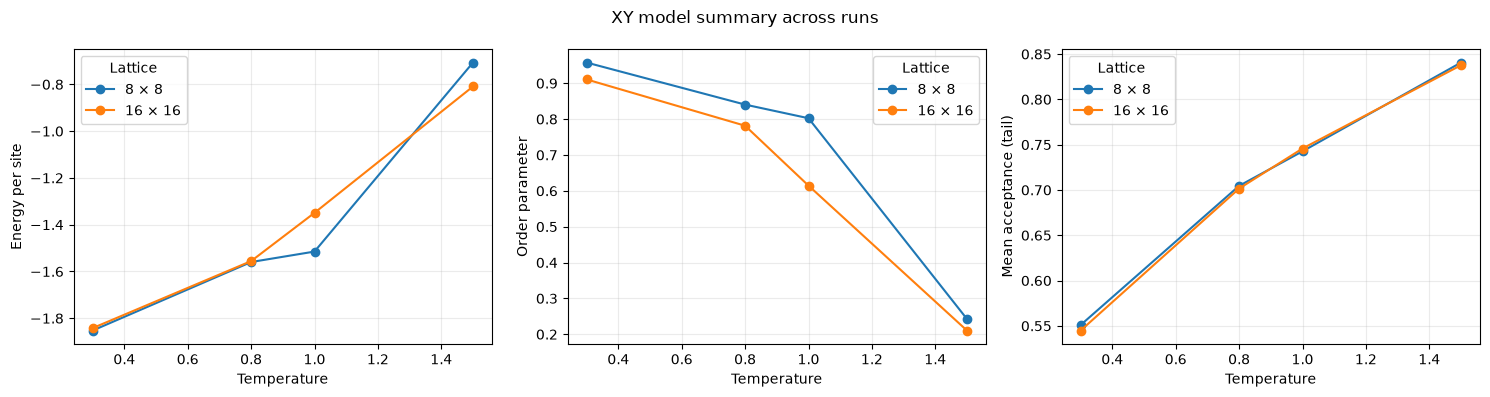

In [4]:
metrics = [
    ('final energy/site', 'Energy per site'),
    ('final order', 'Order parameter'),
    (f'mean acceptance (last {tail} sweeps)', 'Mean acceptance (tail)'),
]
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (column, ylabel) in zip(axes, metrics):
    for n in sizes:
        part = [row for row in summary if row['size'] == n]
        ax.plot([row['temperature'] for row in part], [row[column] for row in part], marker='o', label=f'{n} × {n}')
    ax.set(xlabel='Temperature', ylabel=ylabel)
    ax.grid(alpha=0.25)
    ax.legend(title='Lattice')
fig.suptitle('XY model summary across runs')
fig.tight_layout()
plt.show()

## Inspect time histories

Pick one size and compare its histories across temperatures. This produces a single three-panel figure, regardless of how many runs are in the parameter grid.

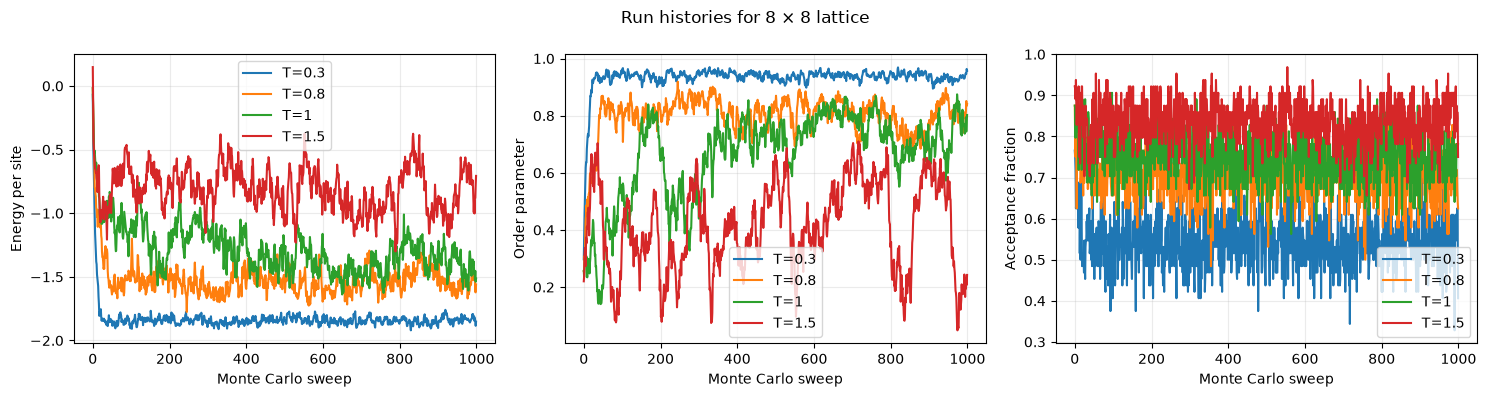

In [5]:
history_size = sizes[0]  # change to another value in sizes if desired
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for T in temperatures:
    run = results[(history_size, T)]
    axes[0].plot(run['energy'], label=f'T={T:g}')
    axes[1].plot(run['order'], label=f'T={T:g}')
    axes[2].plot(run['acceptance'], label=f'T={T:g}')
for ax, label in zip(axes, ['Energy per site', 'Order parameter', 'Acceptance fraction']):
    ax.set(xlabel='Monte Carlo sweep', ylabel=label)
    ax.grid(alpha=0.25)
    ax.legend()
fig.suptitle(f'Run histories for {history_size} × {history_size} lattice')
fig.tight_layout()
plt.show()

## Arrow plots for selected configurations

Use `selected_configs` to choose only a few runs to render. Each arrow figure is made by the existing `plot_results` function, which also displays its energy, order, and acceptance histories. Keep this list short (for example, two or three entries) to avoid a large stack of plots. Entries must be `(size, temperature)` pairs present in the run grid.

Final configuration: 8 × 8, T=0.3


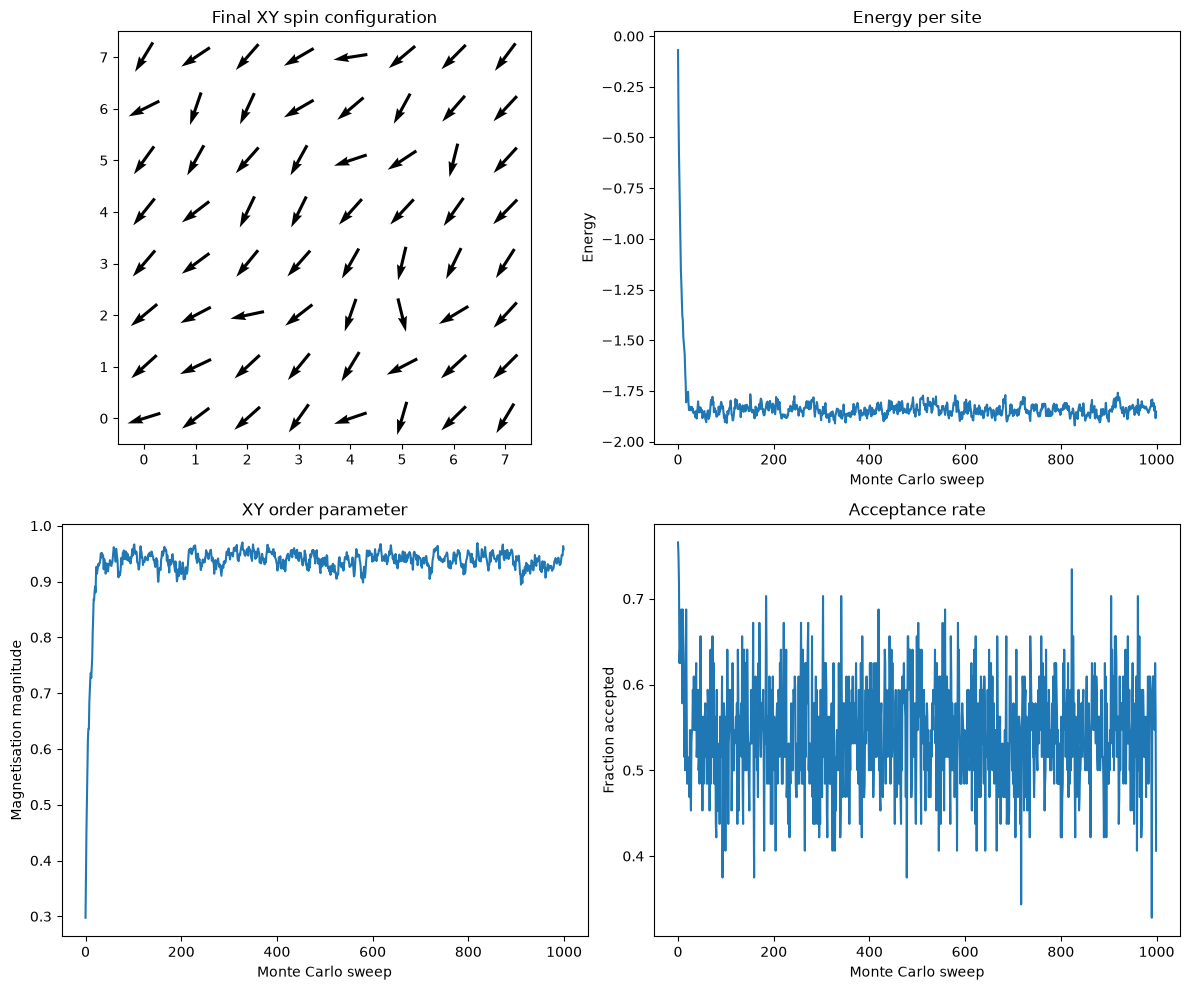

Final configuration: 16 × 16, T=1.5


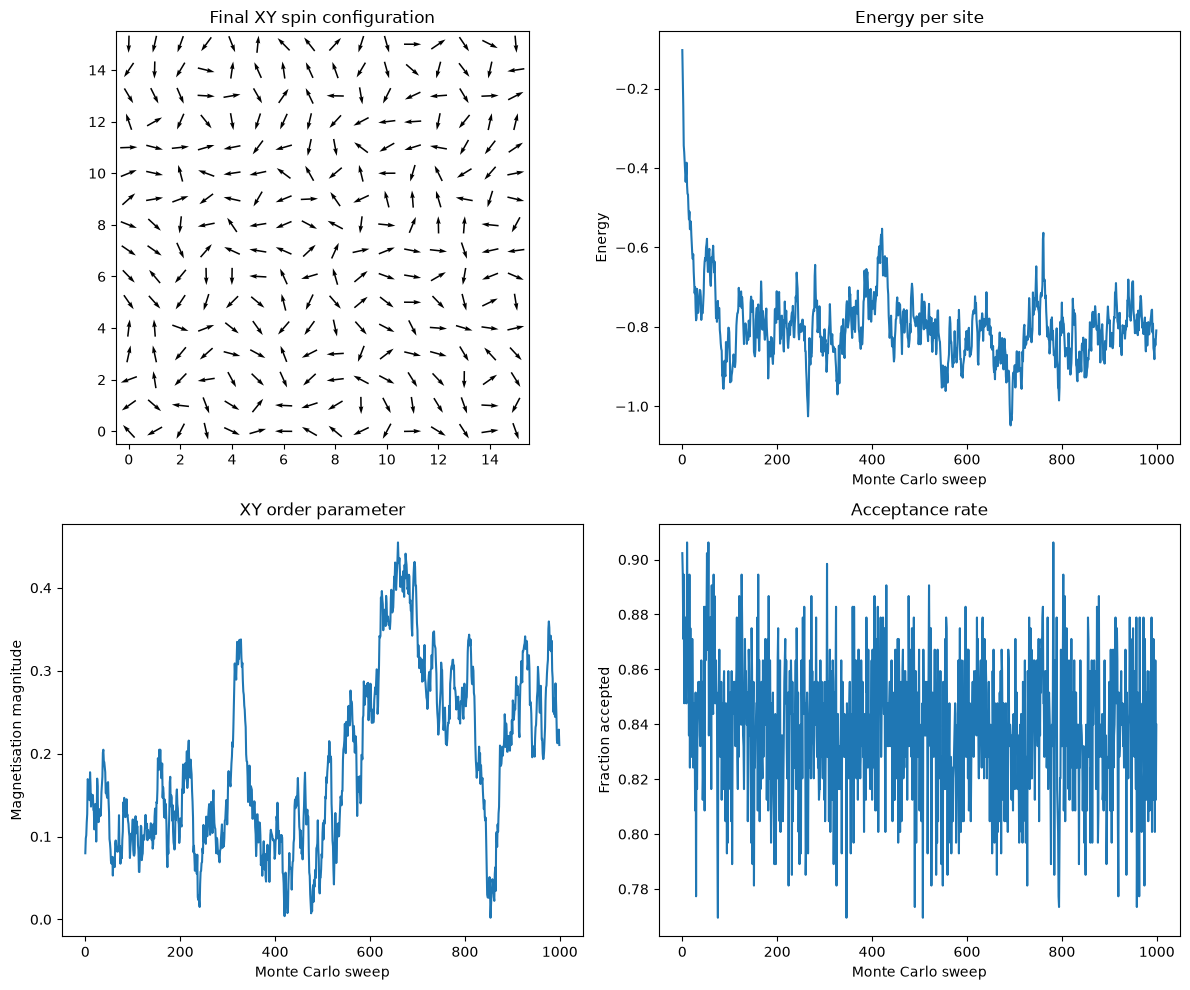

In [6]:
from xy_model import plot_results

selected_configs = [(sizes[0], temperatures[0]), (sizes[-1], temperatures[-1])]
for key in selected_configs:
    if key not in results:
        raise KeyError(f'{key} is not among the completed parameter combinations')
    run = results[key]
    print(f'Final configuration: {key[0]} × {key[0]}, T={key[1]:g}')
    plot_results(run['theta'], run['energy'], run['order'], run['acceptance'])